In [ ]:
import os
import glob
import shutil

import numpy as np
import cv2
import matplotlib.pyplot as plt
import yaml
from tqdm.contrib.concurrent import thread_map# or thread_map

In [2]:
def create_project_file(file_pth: str, dataset_pth: str, label_mapping: dict, val_folder: str = "images/val") -> None:
    data = {
        "path": dataset_pth,
        "train": "images/train",
        "val": val_folder,
        "kpt_shape": [1, 2],
    }

    with open(file_pth, "wt") as f:
        yaml.dump(data, f, sort_keys=False, default_flow_style=None)
    
    with open(file_pth, "at") as f:
        yaml.dump({"names": label_mapping}, f, sort_keys=False)

In [3]:
def get_files_glob(directory, ext="*.txt"):
    pattern = os.path.join(directory, '**', ext)
    txt_files = glob.glob(pattern, recursive=True)
    return txt_files

In [27]:

# === Shared Constants ===
CORRECTION_MATRIX = np.array([
    [1.86,  0.00, -0.05],  # R
    [-0.16, 0.95, -0.53],  # G
    [-0.53, 0.07,  2.27]   # B
], dtype=np.float32)

# === Utilities ===

def srgb_oetf(lum: np.ndarray) -> np.ndarray:
    """sRGB Opto-Electronic Transfer Function (OETF)"""
    out = np.empty_like(lum)
    mask = lum <= 0.0031308
    out[mask] = 12.92 * lum[mask]
    out[~mask] = 1.055 * np.power(lum[~mask], 1 / 2.4) - 0.055
    return out

def prepare_gamma_lut() -> np.ndarray:
    """Create a 256-entry gamma LUT using sRGB OETF"""
    lut = np.empty(256, dtype=np.uint8)
    for i in range(256):
        lum = i / 255.0
        gamma = srgb_oetf(np.array([lum], dtype=np.float32))[0]
        lut[i] = np.clip(np.round(gamma * 255), 0, 255).astype(np.uint8)
    return lut


# === Vectorized White Balance ===
def white_balance_vectorized(image: np.ndarray) -> np.ndarray:
    """
    Vectorized white balance method.
    This method combines color correction and gray-world white balancing.
    """
    assert image.dtype == np.uint8 and image.ndim == 3 and image.shape[2] == 3

    img_float = image.astype(np.float32)
    corrected = np.tensordot(img_float, CORRECTION_MATRIX.T, axes=([2], [1]))
    corrected = np.clip(corrected, 0, 255)

    lut = prepare_gamma_lut()
    corrected_gamma = lut[corrected.astype(np.uint8)]

    mean_rgb = corrected_gamma.mean(axis=(0, 1), dtype=np.float32)
    mean_gray = mean_rgb.mean()
    scale = mean_gray / mean_rgb
    balanced = corrected_gamma.astype(np.float32) * scale

    balanced = np.clip(balanced, 0, 255).astype(np.uint8)
    return balanced

def clahe(img):
    # Improve contrast using histogram equalization (adaptive for better results)
    lab = cv2.cvtColor(img.copy(), cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    l = clahe.apply(l)
    enhanced_image = cv2.merge((l, a, b))
    enhanced_image = cv2.cvtColor(enhanced_image, cv2.COLOR_LAB2RGB)
    return enhanced_image

def blur(img):
    # Apply Gaussian blur to reduce noise
    blurred_image = cv2.GaussianBlur(img, (3, 3), 0)
    return blurred_image

In [28]:
BASE_PTH = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_3_margin_15/images/train"

img_paths = glob.glob(os.path.join(BASE_PTH, "*.jpg"))
len(img_paths)

1307

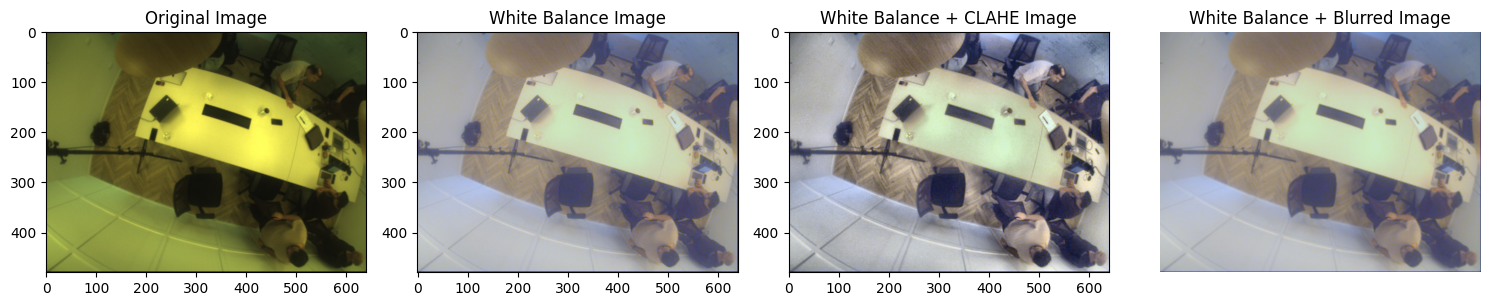

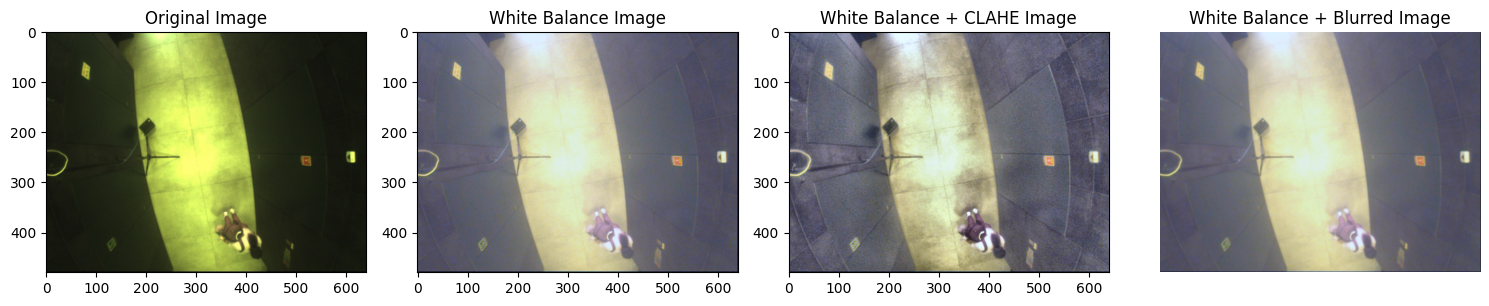

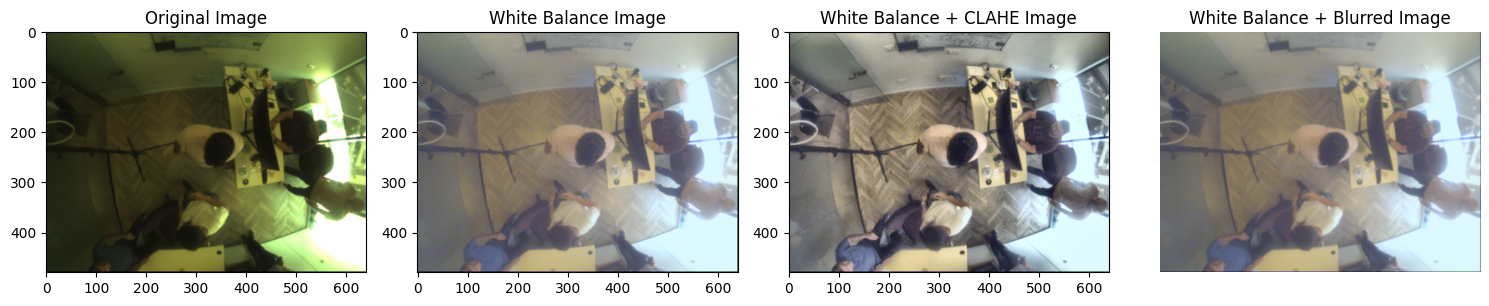

In [29]:
for i in img_paths[:3]:
    img = cv2.imread(i)

    # Apply white balance and contrast enhancement
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_wb = white_balance_vectorized(img_rgb)
    img_wb_clahe = clahe(img_wb)
    img_wb_blurred = blur(img_wb)

    # Display the images
    plt.figure(figsize=(15, 6))
    plt.subplot(1, 4, 1)
    plt.imshow(img_rgb)
    plt.title('Original Image')
    
    plt.subplot(1, 4, 2)
    plt.imshow(img_wb)
    plt.title('White Balance Image')
    
    plt.subplot(1, 4, 3)
    plt.imshow(img_wb_clahe)
    plt.title('White Balance + CLAHE Image')
    
    plt.subplot(1, 4, 4)
    plt.imshow(img_wb_blurred)
    plt.title('White Balance + Blurred Image')
    plt.axis('off')
    plt.tight_layout()
    
    plt.show()

In [30]:
BASE_PTH = "/home/klymy/data/cam4_revB/yolo_dataset"
BASE_DATASET = "batch1_3_margin_15"
PROCESSED_DATASETS = ["batch1_3_margin_15_wb_alif", "batch1_3_margin_15_wb_alif_clahe", "batch1_3_margin_15_wb_alif_blurred"]

SUBSETS = ["train", "val", "holdout"]

In [31]:
def process_file(pth):
    img = cv2.imread(pth)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    res = white_balance_vectorized(img_rgb)
    res = cv2.cvtColor(res, cv2.COLOR_RGB2BGR)
    cv2.imwrite(pth, res)

    return 1

def process_file_clahe(pth):
    img = cv2.imread(pth)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    res = white_balance_vectorized(img_rgb)
    res = clahe(res)
    res = cv2.cvtColor(res, cv2.COLOR_RGB2BGR)
    cv2.imwrite(pth, res)

    return 1

def process_file_blurred(pth):
    img = cv2.imread(pth)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    res = white_balance_vectorized(img_rgb)
    res = blur(res)
    res = cv2.cvtColor(res, cv2.COLOR_RGB2BGR)
    cv2.imwrite(pth, res)

    return 1

In [34]:
for dataset_pth, f in zip(PROCESSED_DATASETS, [process_file, process_file_clahe, process_file_blurred]):
    src_pth = os.path.join(BASE_PTH, BASE_DATASET)
    dst_pth = os.path.join(BASE_PTH, dataset_pth)
    if os.path.exists(dst_pth):
        shutil.rmtree(dst_pth)
    shutil.copytree(src_pth, dst_pth)

    cache_files = get_files_glob(dst_pth, "*.cache")
    for i in cache_files:
        os.remove(i)
    
    # create project file
    create_project_file(os.path.join(dst_pth, "project.yaml"), dst_pth, {0: "person"})
    create_project_file(os.path.join(dst_pth, "project_holdout.yaml"), dst_pth, {0: "person"}, "images/holdout")
    
    img_pths = get_files_glob(os.path.join(dst_pth, "images"), "*.jpg")
    print(len(img_pths))

    r = thread_map(f, img_pths, max_workers=8)
    count = 0
    for i in r:
        count += i

    print(count == len(img_pths))

1600


  0%|          | 0/1600 [00:00<?, ?it/s]

True
1600


  0%|          | 0/1600 [00:00<?, ?it/s]

True
1600


  0%|          | 0/1600 [00:00<?, ?it/s]

True
